#**Netflix Movies & TV Shows – Exploratory Data Analysis (EDA)**
Python | Pandas | NumPy | Matplotlib | Seaborn

Netflix Movies & TV Shows – Project Phases
1. Data Understanding
2. Data Quality Analysis
3. Data Cleaning & Preparation
4. Content Type Analysis (Movies vs TV Shows)
5. Release Year Analysis
6. Netflix Content Growth Analysis
7. Genre Analysis
8. Country-wise Content Analysis
9. Ratings Analysis
10. Movie Duration Analysis
11. TV Show Season Analysis
12. Director & Cast Analysis
13. Time-Based Analysis
14. Statistical Analysis
15. Correlation & Relationship Analysis
16. Final Insights & Business Recommendations
17. Project Conclusion

# Phase 1 – Data Understanding

In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [91]:
import os

print(os.listdir('/'))
print(os.path.exists('/netflix_P1.csv'))

['bin', 'sbin', 'lib', 'opt', 'media', 'usr', 'proc', 'var', 'sys', 'mnt', 'lib64', 'dev', 'tmp', 'root', 'boot', 'etc', 'run', 'srv', 'home', 'netflix_P1.csv', 'kaggle', 'content', '.dockerenv', 'backend-container', 'tools', 'datalab', 'python-apt', 'python-apt.tar.xz', 'sbin.usr-is-merged', 'bin.usr-is-merged', 'lib.usr-is-merged']
True


In [92]:
df = pd.read_csv('/netflix_P1.csv')

df.head()

,show_id,title,type,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s00001,The Last Horizon,TV Show,David Lee,"James Taylor, Olivia Lee",Nigeria,2025-02-18,1990,TV-14,4 Seasons,Thriller,"A thriller tv show exploring stories, relation..."
1,s00002,City of Dreams,Movie,Maria Garcia,"Olivia Lee, Daniel Kim, Michael Davis",Brazil,2021-01-27,2015,R,85 min,Horror Movies,"A horror movies movie exploring stories, relat..."
2,s00003,Hidden Truth,Movie,Maria Garcia,"Sophia Smith, Emma Wilson, Daniel Kim",Brazil,2025-08-05,2020,TV-PG,140 min,Drama,"A drama movie exploring stories, relationships..."
3,s00004,Beyond the Sea,Movie,Olivia Thomas,Emma Wilson,United States,2021-05-22,2011,TV-Y,52 min,Drama,"A drama movie exploring stories, relationships..."
4,s00005,Midnight Stories,TV Show,Robert Taylor,James Taylor,United States,2025-05-10,1998,R,3 Seasons,Drama,"A drama tv show exploring stories, relationshi..."


In [93]:
#no. of row colums
df.shape

#dtype
df.info()

#check statistical summary
df.describe(include='all')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2512 entries, 0 to 2511
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       2512 non-null   object
 1   title         2512 non-null   object
 2   type          2512 non-null   object
 3   director      2273 non-null   object
 4   cast          2357 non-null   object
 5   country       2497 non-null   object
 6   date_added    2502 non-null   object
 7   release_year  2512 non-null   int64 
 8   rating        2500 non-null   object
 9   duration      2504 non-null   object
 10  listed_in     2512 non-null   object
 11  description   2512 non-null   object
dtypes: int64(1), object(11)
memory usage: 235.6+ KB


,show_id,title,type,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,2512,2512,2512,2273,2357,2497,2502,2512.000000,2500,2504,2512,2512
unique,2500,2500,2,15,841,15,1638,NaN,10,139,15,29
top,s00981,Broken Promise 981,Movie,Noah Williams,James Taylor,United States,2026-11-09,NaN,TV-MA,1 Seasons,Drama,"A drama movie exploring stories, relationships..."
freq,2,2,1726,180,74,596,6,NaN,508,292,383,295
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2007.528264,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10.378308,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1990.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1999.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2007.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2016.000000,NaN,NaN,NaN,NaN


In [94]:
df.isnull().sum()

,0
show_id,0
title,0
type,0
director,239
cast,155
country,15
date_added,10
release_year,0
rating,12
duration,8


In [95]:
df.duplicated().sum()

np.int64(11)

###Phase 1 – Data Understanding
Explored the Netflix dataset using Python and Pandas to understand its structure, dimensions, columns, data types, and statistical summaries. This helped identify important variables and understand the dataset before further analysis.

# Phase 2 - Data Quality Investigation

In [96]:
#Missing value percentage
(df.isnull().sum() / len(df)) * 100

,0
show_id,0.000000
title,0.000000
type,0.000000
director,9.514331
cast,6.170382
country,0.597134
date_added,0.398089
release_year,0.000000
rating,0.477707
duration,0.318471


In [97]:
#duplicate values
df[df.duplicated()]

,show_id,title,type,director,cast,country,date_added,release_year,rating,duration,listed_in,description
2500,s01560,Unknown Roads 1560,Movie,Raj Kumar,"Daniel Kim, Lucas Martin",United States,2020-02-18,2012,TV-MA,104 min,Sci-Fi & Fantasy,"A sci-fi & fantasy movie exploring stories, re..."
2501,s01075,Kingdom of Fire 1075,TV Show,David Lee,"Lucas Martin, Ava Brown, Olivia Lee",India,2023-04-23,2022,TV-Y,3 Seasons,Reality TV,"A reality tv tv show exploring stories, relati..."
2502,s01708,New Beginnings 1708,TV Show,Sophia Clark,Olivia Lee,Canada,2025-05-03,2017,TV-MA,1 Seasons,Action,"A action tv show exploring stories, relationsh..."
2503,s01393,Family Ties 1393,Movie,David Lee,"Lucas Martin, Ryan Thomas, Sara Khan",India,2021-07-01,2009,R,169 min,Drama,"A drama movie exploring stories, relationships..."
2504,s01598,Wild Earth 1598,TV Show,Robert Taylor,Michael Davis,United States,2019-09-25,2001,R,3 Seasons,Kids' TV,"A kids' tv tv show exploring stories, relation..."
2505,s00981,Broken Promise 981,Movie,John Smith,Sara Khan,Brazil,2019-07-22,1992,R,118 min,Romantic Movies,"A romantic movies movie exploring stories, rel..."
2506,s01900,The Final Game 1900,Movie,NaN,"Mia Garcia, Priya Sharma",United Kingdom,2022-09-01,2009,TV-14,71 min,Documentaries,"A documentaries movie exploring stories, relat..."
2507,s00733,Family Ties 733,Movie,Robert Taylor,NaN,Australia,2024-07-21,2010,TV-14,87 min,Horror Movies,"A horror movies movie exploring stories, relat..."
2508,s01816,Lost in Time 1816,TV Show,John Smith,Mia Garcia,United States,2021-09-25,2000,G,2 Seasons,International Movies,A international movies tv show exploring stori...
2510,s01395,The Journey Home 1395,TV Show,Daniel Martin,"Sophia Smith, Lucas Martin",India,2025-05-15,1991,TV-Y7,2 Seasons,Children & Family,"A children & family tv show exploring stories,..."


In [98]:
#unique type
df['type'].unique()

array(['TV Show', 'Movie'], dtype=object)

In [99]:
#Number of unique values per column
df.nunique()

,0
show_id,2500
title,2500
type,2
director,15
cast,841
country,15
date_added,1638
release_year,36
rating,10
duration,139


In [100]:
#earliest movie
df['release_year'].min()

1990

In [101]:
#recent movie
df['release_year'].max()

2025

In [102]:
#Check missing values in percentage

missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.sort_values(ascending=False))

director        9.514331
cast            6.170382
country         0.597134
rating          0.477707
date_added      0.398089
duration        0.318471
show_id         0.000000
title           0.000000
type            0.000000
release_year    0.000000
listed_in       0.000000
description     0.000000
dtype: float64


In [103]:
#Check inconsistent content types

df['type'].value_counts()

,count
type,
Movie,1726
TV Show,786


In [104]:
#Check rating categories

df['rating'].value_counts()

,count
rating,
TV-MA,508
TV-14,476
TV-PG,299
PG-13,289
R,264
PG,193
G,174
TV-G,161
TV-Y,90


In [105]:
#Check duration inconsistencies

df['duration'].value_counts(dropna=False).head(15)

,count
duration,
1 Seasons,292
2 Seasons,211
3 Seasons,165
4 Seasons,87
113 min,33
119 min,33
96 min,33
117 min,32
98 min,31


In [106]:
#check date format
df['date_added'].head(10)

,date_added
0,2025-02-18
1,2021-01-27
2,2025-08-05
3,2021-05-22
4,2025-05-10
5,2024-01-18
6,2023-05-06
7,2020-02-01
8,2026-12-02
9,2023-12-02


In [107]:
#Check duplicate IDs

df['show_id'].duplicated().sum()

np.int64(12)

In [108]:
#Check unexpected content types

df['type'].value_counts(dropna=False)

,count
type,
Movie,1726
TV Show,786


In [109]:
#Check blank or whitespace-only titles

(df['title'].str.strip() == '').sum()

np.int64(0)

###Phase 2 - Data Quality Investigation
The dataset was investigated to identify data-quality issues, including missing values, duplicate records, inconsistent data types, and unexpected values. The Director and Rating columns were found to contain missing information. The date_added column was stored as an object datatype, and the duration column contained both minutes and seasons. These issues were identified for further data preparation.

# Phase - 3 data cleaning
Objective: Prepare the Netflix dataset by fixing missing information, removing duplicate records, and converting columns into useful formats for analysis.

In [110]:
#create working copy

df_clean = df.copy()
df_clean.head()

,show_id,title,type,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s00001,The Last Horizon,TV Show,David Lee,"James Taylor, Olivia Lee",Nigeria,2025-02-18,1990,TV-14,4 Seasons,Thriller,"A thriller tv show exploring stories, relation..."
1,s00002,City of Dreams,Movie,Maria Garcia,"Olivia Lee, Daniel Kim, Michael Davis",Brazil,2021-01-27,2015,R,85 min,Horror Movies,"A horror movies movie exploring stories, relat..."
2,s00003,Hidden Truth,Movie,Maria Garcia,"Sophia Smith, Emma Wilson, Daniel Kim",Brazil,2025-08-05,2020,TV-PG,140 min,Drama,"A drama movie exploring stories, relationships..."
3,s00004,Beyond the Sea,Movie,Olivia Thomas,Emma Wilson,United States,2021-05-22,2011,TV-Y,52 min,Drama,"A drama movie exploring stories, relationships..."
4,s00005,Midnight Stories,TV Show,Robert Taylor,James Taylor,United States,2025-05-10,1998,R,3 Seasons,Drama,"A drama tv show exploring stories, relationshi..."


In [111]:
#handling missing values

df_clean.isnull().sum()

,0
show_id,0
title,0
type,0
director,239
cast,155
country,15
date_added,10
release_year,0
rating,12
duration,8


In [112]:
columns=['director','cast','country','rating']
df_clean[columns] = df_clean[columns].fillna('Unknown')
df_clean.isnull().sum()

,0
show_id,0
title,0
type,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,8


In [113]:
#removing duplicated records

df_clean.duplicated().sum()

df_clean = df_clean.drop_duplicates()
df_clean.duplicated().sum()


np.int64(0)

In [114]:
#covert date_added to datetime format

df_clean['date_added'] = pd.to_datetime(df_clean['date_added'])
df_clean['date_added'].dtype

dtype('<M8[ns]')

In [115]:
#Separate movie duration and TV seasons

df_clean['duration_int'] = (
    df_clean['duration']
    .str.extract(r'(\d+)')
    .astype('float')
)

In [116]:
df_clean['movie_duration'] = df_clean['duration_int'].where(
    df_clean['type'] == 'Movie'
)

df_clean['seasons'] = df_clean['duration_int'].where(
    df_clean['type'] == 'TV Show'
)

### Phase 3 – Data Cleaning & Preparation

Created a working copy of the original dataset and handled missing values in the Director, Cast, Country, and Rating columns by replacing them with "Unknown". Removed exact duplicate records, converted the date_added column into datetime format, and separated movie durations from TV show seasons for further analysis.

# Phase 4 – Content Type Analysis

In [117]:
#Count Movies and TV Shows

df_clean['type'].value_counts()

,count
type,
Movie,1720
TV Show,781


In [118]:
#Calculate percentages

content_percentage = (
    df_clean['type'].value_counts(normalize=True) * 100
)

print(content_percentage.round(2))

type
Movie      68.77
TV Show    31.23
Name: proportion, dtype: float64


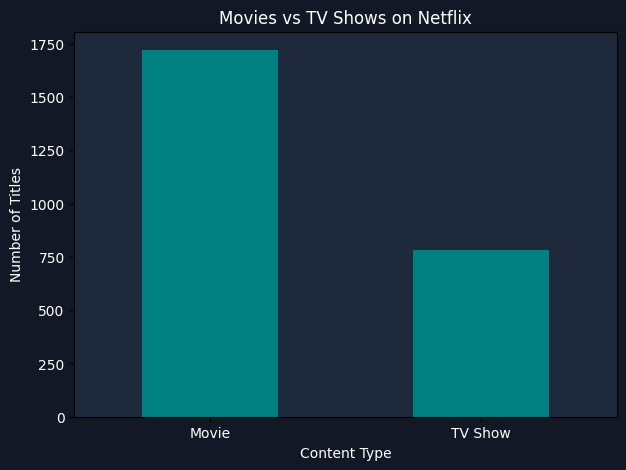

In [119]:
#Create a bar chart

import matplotlib.pyplot as plt

df_clean['type'].value_counts().plot(
    kind='bar',
    color='teal',
    figsize=(7, 5)
)

plt.gcf().set_facecolor('#121826') #entier chart background
plt.gca().set_facecolor('#1E293B') #Inner plotting area background

plt.title('Movies vs TV Shows on Netflix', color='white')
plt.xlabel('Content Type', color='white')
plt.ylabel('Number of Titles', color='white')

plt.xticks(rotation=0, color='white')
plt.yticks(color='white')

plt.show()

###Phase 4 – Content Type Analysis

Analyzed the distribution of Movies and TV Shows using Pandas and Matplotlib. The dataset contains 1,720 Movies (68.77%) and 781 TV Shows (31.23%). The analysis shows that Movies dominate Netflix's content catalogue.

# Phase 5 – Release Year Analysis

* Which release year has the highest number of titles?



* How has Netflix content changed across release years?



* Which years had the most content releases?



In [120]:
#Check the release year column

df_clean['release_year'].head()

,release_year
0,1990
1,2015
2,2020
3,2011
4,1998


In [121]:
#check data type

df_clean['release_year'].dtype

dtype('int64')

In [122]:
#count titles by release year

year_counts=(df_clean['release_year'].value_counts().sort_index())
print(year_counts)

release_year
1990    57
1991    64
1992    56
1993    66
1994    84
1995    70
1996    69
1997    83
1998    66
1999    72
2000    83
2001    75
2002    83
2003    79
2004    65
2005    63
2006    65
2007    77
2008    69
2009    64
2010    59
2011    56
2012    73
2013    73
2014    69
2015    75
2016    61
2017    55
2018    69
2019    56
2020    68
2021    68
2022    83
2023    71
2024    91
2025    64
Name: count, dtype: int64


In [123]:
#Find the year with the most titles

year_counts.idxmax()

np.int64(2024)

In [124]:
#To find the number of titles released in that year

year_counts.max()

91

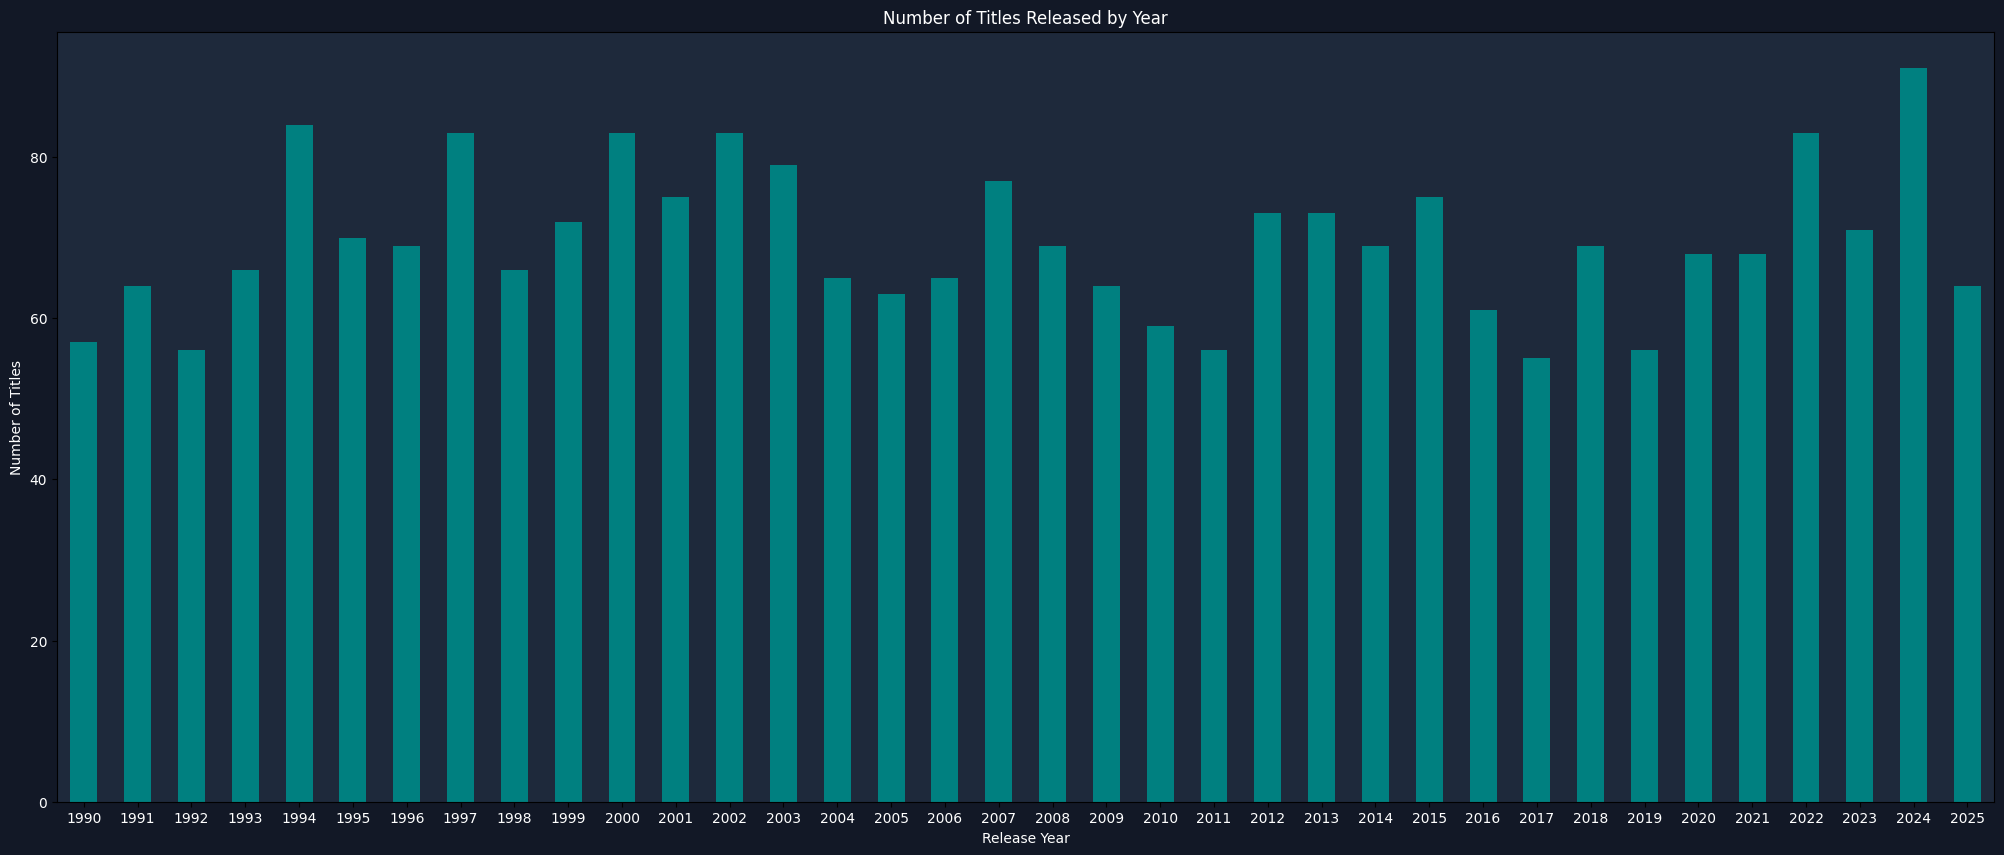

In [125]:
#Create a visualization

year_counts.plot(
    kind='bar',
    color='teal',
    figsize=(25,10)
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Number of Titles Released by Year',color='white')
plt.xlabel('Release Year',color='white')
plt.ylabel('Number of Titles',color='white')

plt.xticks(rotation=0,color='white')
plt.yticks(color='white')

plt.show()

###Phase 5 – Release Year Analysis

Analyzed Netflix content based on its original release year using Pandas and Matplotlib. The release_year column was confirmed to have an integer datatype. The highest number of titles was observed in 2024, with 91 titles. The analysis helped understand the distribution of Netflix content across different release years.

# Phase 6 – Netflix Content Growth Analysis.

Understand how Netflix's content library has grown over time by analyzing when Movies and TV Shows were added to Netflix.

In [126]:
#Check the date_added column

df_clean['date_added'].head()

,date_added
0,2025-02-18
1,2021-01-27
2,2025-08-05
3,2021-05-22
4,2025-05-10


In [127]:
#check datatype

df_clean['date_added'].dtype

dtype('<M8[ns]')

In [128]:
#Extract the year

df_clean['year_added'] = df_clean['date_added'].dt.year

In [129]:
df_clean[['title', 'date_added', 'year_added']].head(10)

,title,date_added,year_added
0,The Last Horizon,2025-02-18,2025.0
1,City of Dreams,2021-01-27,2021.0
2,Hidden Truth,2025-08-05,2025.0
3,Beyond the Sea,2021-05-22,2021.0
4,Midnight Stories,2025-05-10,2025.0
5,The Silent House,2024-01-18,2024.0
6,Code Breakers,2023-05-06,2023.0
7,Wild Earth,2020-02-01,2020.0
8,Love Again,2026-12-02,2026.0
9,The Final Game,2023-12-02,2023.0


In [130]:
#year_added_counts = df_clean['year_added'].value_counts().sort_index()

year_added_counts = df_clean['year_added'].value_counts().sort_index()
print(year_added_counts)

year_added
2018.0    221
2019.0    234
2020.0    224
2021.0    248
2022.0    246
2023.0    285
2024.0    342
2025.0    338
2026.0    353
Name: count, dtype: int64


In [131]:
#Find the year with the most additions

print("year :",year_added_counts.idxmax())
print("number of additions :",year_added_counts.max())

year : 2026.0
number of additions : 353


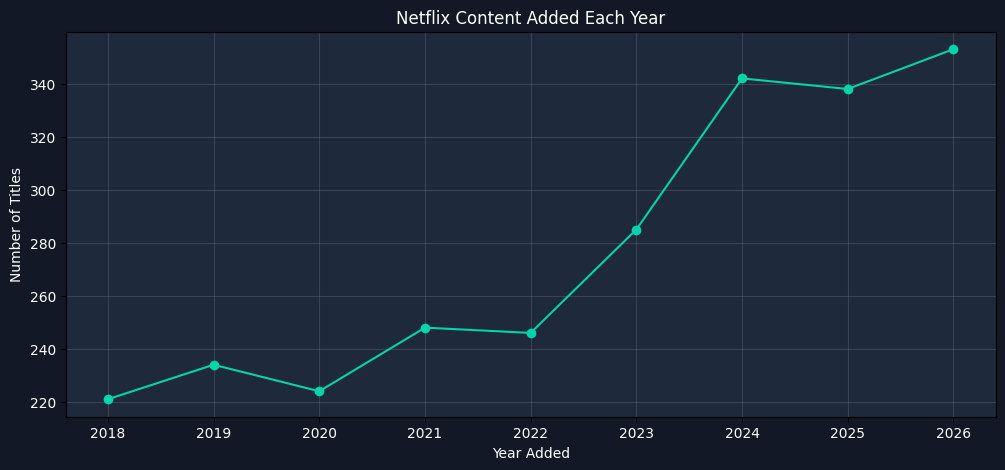

In [132]:
#visualize content growth

year_added_counts.plot(
    kind='line',
    figsize=(12, 5),
    marker='o',
    color='#00D4AA'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Netflix Content Added Each Year', color='white')
plt.xlabel('Year Added', color='white')
plt.ylabel('Number of Titles', color='white')

plt.xticks(color='white')
plt.yticks(color='white')
plt.grid(color='gray', alpha=0.3)

plt.show()

Phase 6 – Netflix Content Growth Analysis

Analyzed Netflix content additions over time using the date_added column. Extracted the year into a new column called year_added and calculated the number of titles added each year. The analysis revealed that content additions fluctuate rather than showing constant growth. Future-dated records were also identified for further investigation.

# Phase 7 – Genre Analysis
Understand which genres are most common on Netflix and identify the top 10 genres.

In [133]:
#Explore the listed_in column

df_clean['listed_in'].head(10)

,listed_in
0,Thriller
1,Horror Movies
2,Drama
3,Drama
4,Drama
5,Documentaries
6,Kids' TV
7,Crime TV Shows
8,Children & Family
9,Comedy


In [134]:
#Split the genres

genres = df_clean['listed_in'].dropna().str.split(',')

In [135]:
#count each genres

from collections import Counter

genre_counts = Counter(
    genre
    for genre_list in genres
    for genre in genre_list
)

print(genre_counts.most_common(10))

[('Drama', 382), ('Action', 230), ('International Movies', 224), ('Comedy', 221), ('Thriller', 216), ('Sci-Fi & Fantasy', 182), ('Documentaries', 176), ('Romantic Movies', 154), ('Children & Family', 143), ('Stand-Up Comedy', 137)]


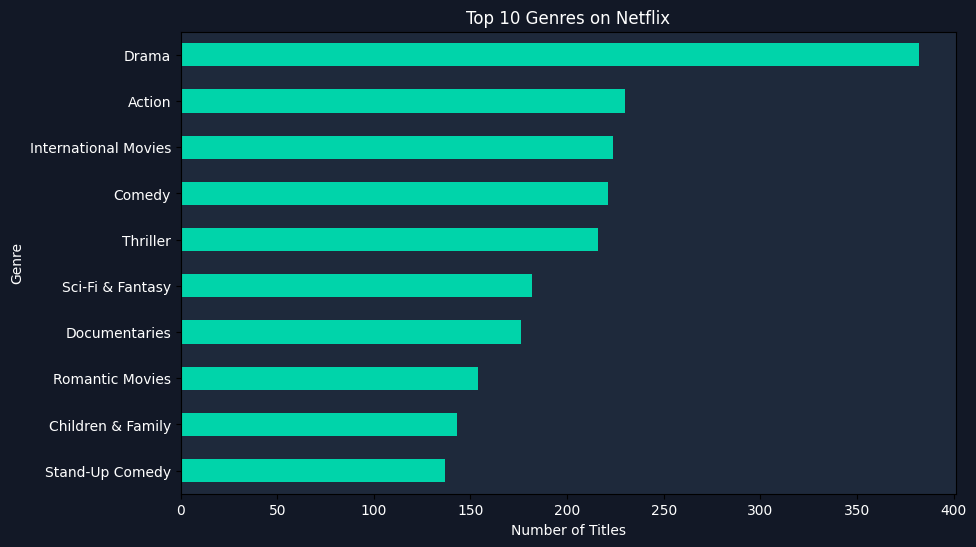

In [136]:
#reate a top 10 genre chart

top_genres = pd.Series(dict(genre_counts.most_common(10)))

top_genres.sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    color='#00D4AA'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Top 10 Genres on Netflix', color='white')
plt.xlabel('Number of Titles', color='white')
plt.ylabel('Genre', color='white')

plt.xticks(color='white')
plt.yticks(color='white')

plt.show()

### Phase 7 – Genre Analysis

Analyzed Netflix content genres using Pandas and Python's Counter function. Split multiple genres from the listed_in column and calculated their frequency. Drama was the most common genre with 382 appearances, followed by Action with 230. The analysis revealed that Drama is significantly more represented than other genres in the dataset.

#Phase 8 – Country Analysis

Understand which countries contribute the most Movies and TV Shows to Netflix.

In [137]:
#explore the country column

df_clean['country'].head(10)

,country
0,Nigeria
1,Brazil
2,Brazil
3,United States
4,United States
5,United States
6,India
7,France
8,South Korea
9,Brazil


In [138]:
#check missing values

df_clean['country'].isnull().sum()

(df_clean['country'] == 'Unknown').sum()

np.int64(15)

In [139]:
#Split multiple countries

countries = df_clean['country'].dropna().str.split(',')

In [140]:
#Count country appearances

from collections import Counter

country_counts = Counter(
    country
    for country_list in countries
    for country in country_list
)

print(country_counts.most_common(10))

[('United States', 593), ('India', 472), ('South Korea', 184), ('United Kingdom', 178), ('Japan', 160), ('France', 125), ('Canada', 124), ('Mexico', 104), ('Germany', 102), ('Spain', 97)]


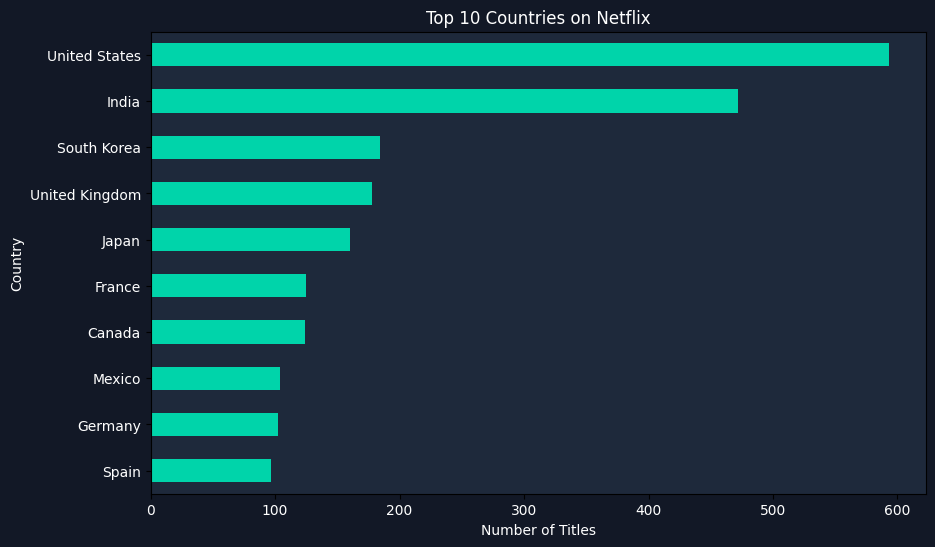

In [141]:
top_countries = pd.Series(dict(country_counts.most_common(10)))

top_countries.sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    color='#00D4AA'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Top 10 Countries on Netflix', color='white')
plt.xlabel('Number of Titles', color='white')
plt.ylabel('Country', color='white')

plt.xticks(color='white')
plt.yticks(color='white')

plt.show()

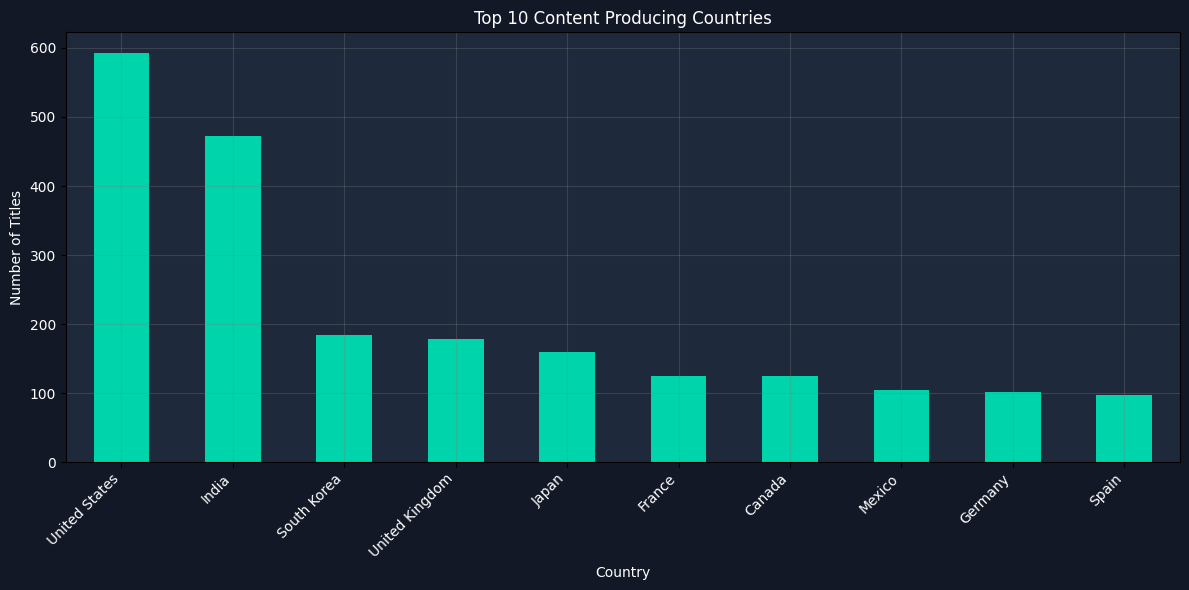

In [142]:
top_countries = pd.Series(dict(country_counts.most_common(10)))

top_countries.plot(
    kind='bar',
    figsize=(12, 6),
    color='#00D4AA'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Top 10 Content Producing Countries', color='white')
plt.xlabel('Country', color='white')
plt.ylabel('Number of Titles', color='white')

plt.xticks(rotation=45, ha='right', color='white')
plt.yticks(color='white')
plt.grid(color='gray', alpha=0.3)

plt.tight_layout()
plt.show()

### Phase 8 – Country Analysis

Analyzed Netflix content by production country using Pandas and Python's Counter function. Identified the top 10 countries and visualized their content distribution using a vertical bar chart. The United States ranked first with 593 appearances, followed by India with 472. The results showed that these two countries have significantly higher representation than the remaining countries.

# Phase 9 – Ratings Analysis.

Understand how Netflix classifies its content based on age suitability and identify the most common content ratings.

In [143]:
#Explore the rating column

df_clean['rating'].head(10)

,rating
0,TV-14
1,R
2,TV-PG
3,TV-Y
4,R
5,TV-MA
6,PG
7,TV-14
8,PG
9,TV-Y


In [144]:
#Check the available rating categories:

df_clean['rating'].unique()

array(['TV-14', 'R', 'TV-PG', 'TV-Y', 'TV-MA', 'PG', 'G', 'TV-G', 'PG-13',
       'TV-Y7', 'Unknown'], dtype=object)

In [145]:
#Count each rating

rating_counts = df_clean['rating'].value_counts()
print(rating_counts)

rating
TV-MA      506
TV-14      474
TV-PG      299
PG-13      289
R          260
PG         193
G          173
TV-G       161
TV-Y        89
TV-Y7       45
Unknown     12
Name: count, dtype: int64


In [146]:
#Find the most common rating

print("Most common rating :",rating_counts.idxmax())
print("Number of titles with the most common rating :",rating_counts.max())

Most common rating : TV-MA
Number of titles with the most common rating : 506


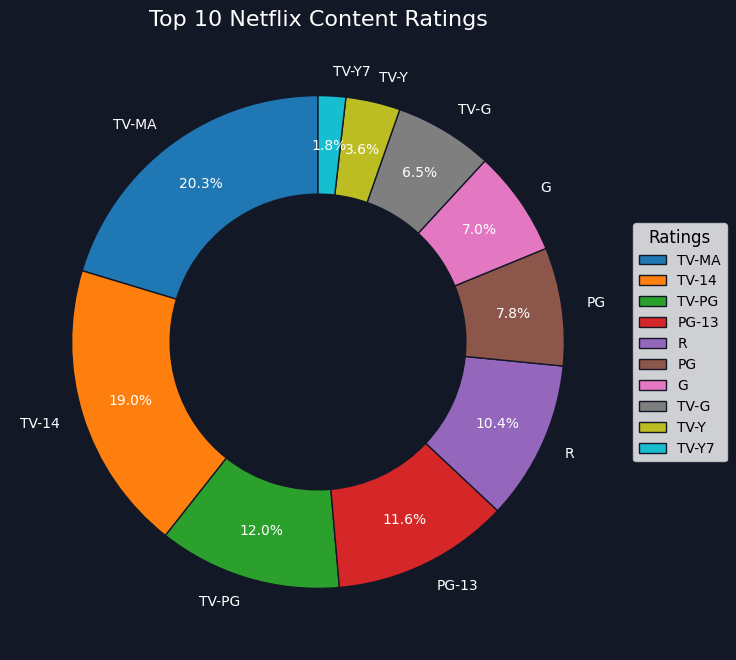

In [147]:
#Visualize the top 10 ratings

import matplotlib.pyplot as plt

top_ratings = rating_counts.head(10)

plt.figure(figsize=(10, 8))

plt.pie(
    top_ratings,
    labels=top_ratings.index,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.80,
    textprops={'color': 'white', 'fontsize': 10},
    wedgeprops={'width': 0.4, 'edgecolor': '#121826'}
)

plt.gcf().set_facecolor('#121826')

plt.title(
    'Top 10 Netflix Content Ratings',
    color='white',
    fontsize=16
)

plt.legend(
    top_ratings.index,
    title='Ratings',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    labelcolor='black',
    title_fontsize=12
)

plt.show()

### Phase 9 – Ratings Analysis

Analyzed Netflix content ratings using Pandas and Matplotlib. Identified TV-MA as the most common rating with 506 titles, followed by TV-14 with 474 titles. The analysis showed that mature and older-teen content classifications are strongly represented in the Netflix catalogue. Also identified 12 records with unknown ratings.

# Phase 10 – Movie Duration Analysis.

Analyze the duration of Netflix movies to understand their runtime distribution.

In [148]:
#Filter only Movies

movies = df_clean[df_clean['type'] == 'Movie'].copy()
print(movies.shape)

(1720, 16)


In [149]:
#calculate descriptive statistics (this gives max min movie)

movies['duration_int'].describe()

,duration_int
count,1715.000000
mean,104.578426
std,24.699456
min,45.000000
25%,87.000000
50%,104.000000
75%,122.000000
max,190.000000


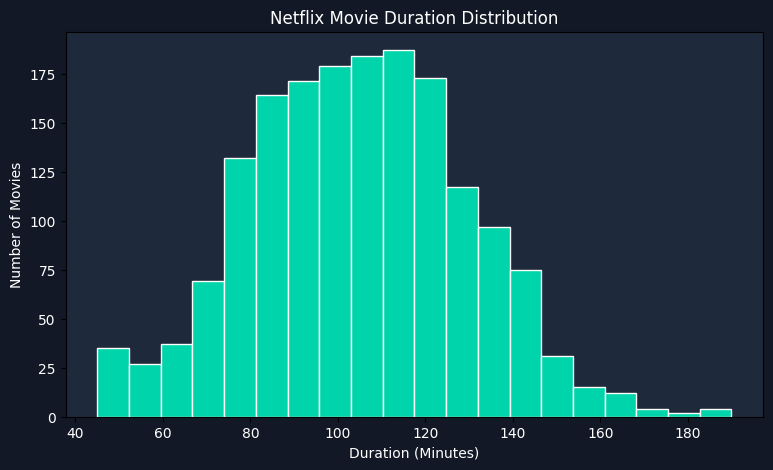

In [150]:
import matplotlib.pyplot as plt

movies['movie_duration'].plot(
    kind='hist',
    bins=20,
    figsize=(9,5),
    edgecolor='white',
    color='#00D4AA'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Netflix Movie Duration Distribution', color='white')
plt.xlabel('Duration (Minutes)', color='white')
plt.ylabel('Number of Movies', color='white')
plt.xticks(color='white')
plt.yticks(color='white')

plt.show()

In [151]:
#Find the Most Common Duration Range

bins = [0, 60, 90, 120, 150, 180, 300]

movies['duration_group'] = pd.cut(
    movies['movie_duration'],
    bins=bins
)

print(movies['duration_group'].value_counts().sort_index())

duration_group
(0, 60]        64
(60, 90]      445
(90, 120]     758
(120, 150]    399
(150, 180]     45
(180, 300]      4
Name: count, dtype: int64


### Phase 10: Movie Duration Analysis

Analyzed Netflix movie durations using Pandas and Matplotlib. The average movie duration was 104.57 minutes, with the shortest movie lasting 45 minutes and the longest lasting 190 minutes. The histogram showed that most movies fall between 80 and 120 minutes, while longer movies are less common.

# Phase 11 – TV Show Season Analysis.

Understand how many seasons Netflix TV shows typically have and identify the most common season count.

In [152]:
#filter tv shows

tv_shows = df_clean[df_clean['type']=='TV Show']
print(tv_shows.shape)

(781, 16)


In [153]:
#Analyze Season Counts

tv_shows['seasons'].describe()

,seasons
count,778.000000
mean,2.170951
std,1.163729
min,1.000000
25%,1.000000
50%,2.000000
75%,3.000000
max,6.000000


In [154]:
#Count Shows by Number of Seasons

season_counts = tv_shows['seasons'].value_counts().sort_index()
print(season_counts)

seasons
1.0    291
2.0    209
3.0    163
4.0     87
5.0     25
6.0      3
Name: count, dtype: int64


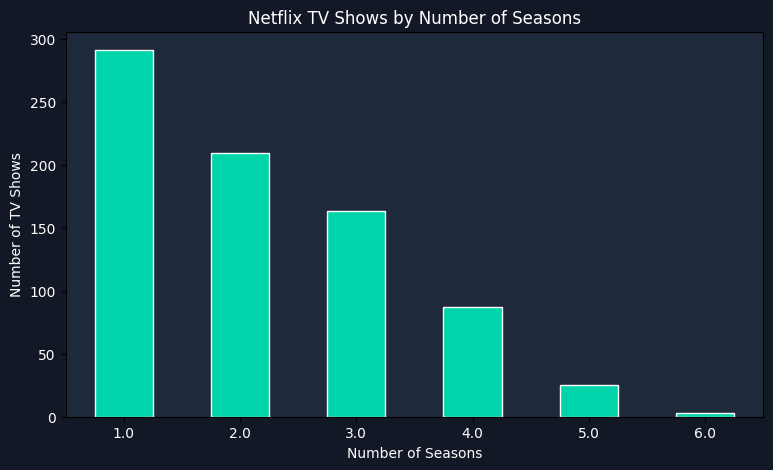

In [155]:
#Visualize Season Distribution

season_counts.plot(
    kind='bar',
    figsize=(9,5),
    color='#00D4AA',
    edgecolor='white'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Netflix TV Shows by Number of Seasons', color='white')
plt.xlabel('Number of Seasons', color='white')
plt.ylabel('Number of TV Shows', color='white')
plt.xticks(rotation=0, color='white')
plt.yticks(color='white')

plt.show()

### Phase 11: TV Show Season Analysis

Analyzed the season distribution of Netflix TV Shows using Pandas and Matplotlib. The average number of seasons was 2.17, with a minimum of 1 and a maximum of 6 seasons. Single-season shows were the most common. The analysis revealed that shorter TV series are more widely represented in the dataset than long-running series.

# Phase 12 – Director & Cast Analysis.
Identify the directors and actors who appear most frequently in Netflix's content catalogue.

In [156]:
#Top 10 Directors

from collections import Counter

directors = df_clean['director'].dropna()

director_counts = Counter(
    director.strip()
    for names in directors
    if names != 'Unknown'
    for director in names.split(',')
)

print(director_counts.most_common(10))

[('Noah Williams', 180), ('Olivia Thomas', 166), ('James Anderson', 166), ('Michael Brown', 157), ('Sarah Wilson', 157), ('Emily Davis', 153), ('Robert Taylor', 149), ('David Lee', 148), ('Maria Garcia', 148), ('Raj Kumar', 148)]


In [157]:
#top 10 actors

actors = df_clean['cast'].dropna()

actor_counts = Counter(
    actor.strip()
    for names in actors
    if names != 'Unknown'
    for actor in names.split(',')
)

print(actor_counts.most_common(10))

[('Ryan Thomas', 367), ('Olivia Lee', 351), ('Sophia Smith', 349), ('James Taylor', 345), ('Arun Kumar', 345), ('Emma Wilson', 343), ('John Carter', 343), ('Ava Brown', 341), ('Michael Davis', 340), ('Sara Khan', 327)]


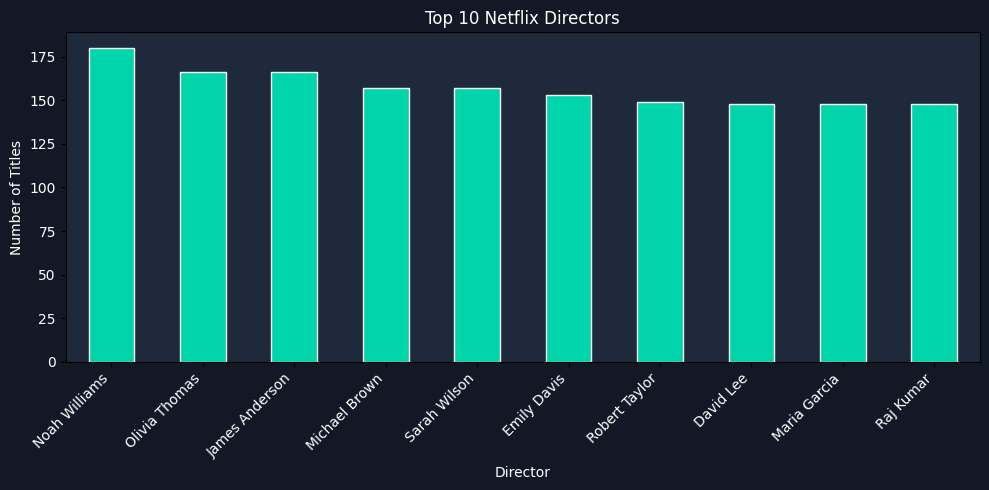

In [158]:
#visualize top 10 director

top_directors = pd.Series(dict(director_counts.most_common(10)))

top_directors.plot(
    kind='bar',
    figsize=(10,5),
    color='#00D4AA',
    edgecolor='white'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Top 10 Netflix Directors', color='white')
plt.xlabel('Director', color='white')
plt.ylabel('Number of Titles', color='white')
plt.xticks(rotation=45, ha='right', color='white')
plt.yticks(color='white')
plt.tight_layout()
plt.show()

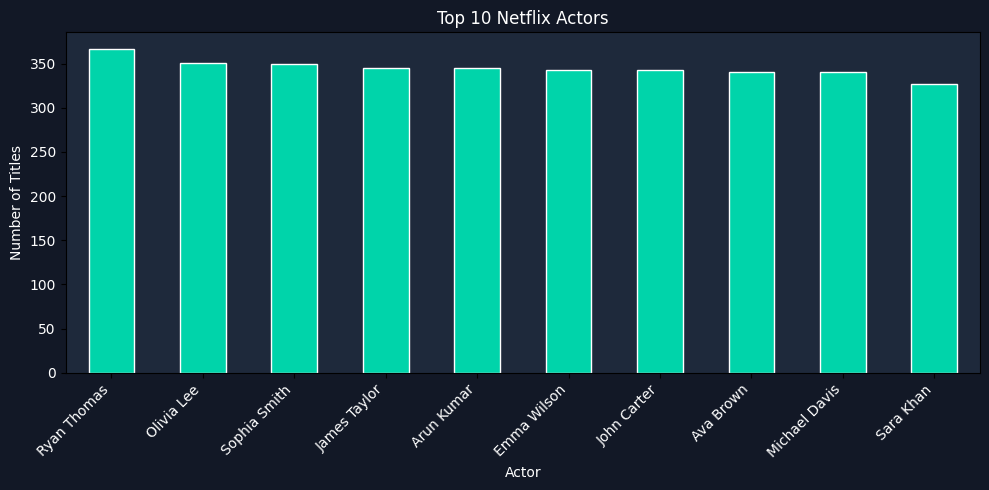

In [159]:
#Visualize Top 10 Actors

top_actors = pd.Series(dict(actor_counts.most_common(10)))

top_actors.plot(
    kind='bar',
    figsize=(10,5),
    color='#00D4AA',
    edgecolor='white'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Top 10 Netflix Actors', color='white')
plt.xlabel('Actor', color='white')
plt.ylabel('Number of Titles', color='white')
plt.xticks(rotation=45, ha='right', color='white')
plt.yticks(color='white')
plt.tight_layout()
plt.show()

### Phase 12: Director & Cast Analysis

Analyzed the most frequently credited directors and actors in Netflix's content catalogue using Pandas and Python's Counter function. Identified the top 10 directors and actors and visualized their appearances using bar charts. The top three actors had relatively close appearance counts, while the top directors also showed a small difference in title counts.

# Phase 13 – Time-Based Analysis.
Identify which months have the highest number of Netflix content additions and understand the timing patterns.

In [160]:
#extract month

df_clean['month_added'] = df_clean['date_added'].dt.month_name()
print(df_clean['month_added'].shape)
print(df_clean['month_added'].head())

(2501,)
0    February
1     January
2      August
3         May
4         May
Name: month_added, dtype: object


In [161]:
#Count Content Added Each Month

month_counts = df_clean['month_added'].value_counts()
print(month_counts)

month_added
September    245
May          227
March        219
December     214
June         212
April        206
November     205
October      198
August       194
January      191
July         191
February     189
Name: count, dtype: int64


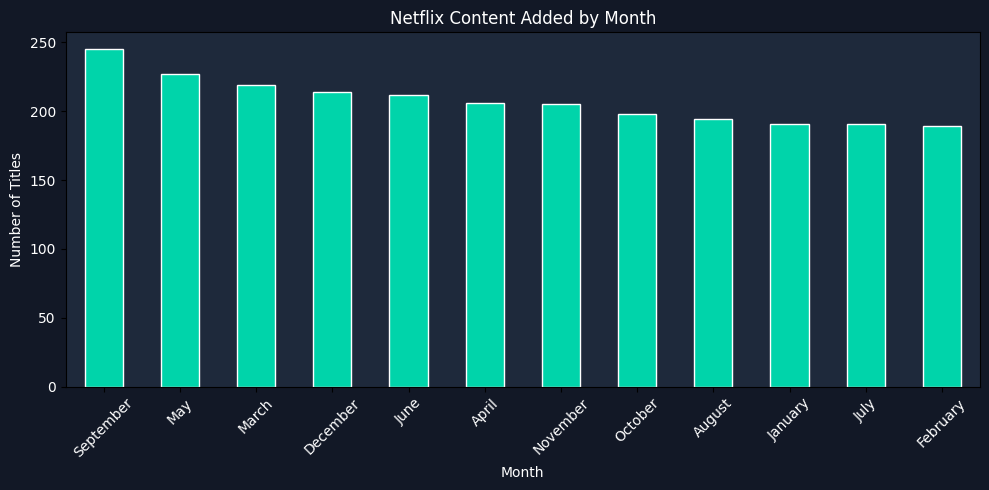

In [162]:
#visualize monthly trends

month_counts.plot(
    kind='bar',
    figsize=(10,5),
    color='#00D4AA',
    edgecolor='white'
)

plt.gcf().set_facecolor('#121826')
plt.gca().set_facecolor('#1E293B')

plt.title('Netflix Content Added by Month', color='white')
plt.xlabel('Month', color='white')
plt.ylabel('Number of Titles', color='white')
plt.xticks(rotation=45, color='white')
plt.yticks(color='white')
plt.tight_layout()
plt.show()

In [163]:
#find highest and lowest month

print("Highest:", month_counts.idxmax(), month_counts.max())
print("Lowest:", month_counts.idxmin(), month_counts.min())

Highest: September 245
Lowest: February 189


### Phase 13: Time-Based Analysis

Analyzed Netflix content additions by month using the date_added column. September recorded the highest number of content additions, while February had the lowest. The monthly distribution showed relatively balanced content additions with some variations across months.

# Phase 14 – Statistical Analysis.
summarize the numerical characteristics of Netflix's content using basic statistics.

In [164]:
#Movie Duration Statistics

print(df_clean[df_clean['type'] == 'Movie']['movie_duration'].describe())

count    1715.000000
mean      104.578426
std        24.699456
min        45.000000
25%        87.000000
50%       104.000000
75%       122.000000
max       190.000000
Name: movie_duration, dtype: float64


In [165]:
#tv show season statistics

print(df_clean[df_clean['type'] == 'TV Show']['seasons'].describe())

count    778.000000
mean       2.170951
std        1.163729
min        1.000000
25%        1.000000
50%        2.000000
75%        3.000000
max        6.000000
Name: seasons, dtype: float64


In [166]:
#compare movie and tv show

print("Average Movie Duration:",
      df_clean[df_clean['type'] == 'Movie']['movie_duration'].mean())

print("Average TV Show Seasons:",
      df_clean[df_clean['type'] == 'TV Show']['seasons'].mean())

Average Movie Duration: 104.57842565597667
Average TV Show Seasons: 2.170951156812339


In [167]:
#Content Distribution Percentage

content_percentage = df_clean['type'].value_counts(normalize=True) * 100
print(content_percentage.round(2))

type
Movie      68.77
TV Show    31.23
Name: proportion, dtype: float64


### Phase 14: Statistical Analysis

Performed statistical analysis on Netflix Movies and TV Shows using Pandas. The average movie duration was 104.58 minutes, while TV Shows had an average of 2.17 seasons. Movies accounted for 68.77% of the dataset, compared to 31.23% for TV Shows. The analysis confirmed that Movies form the majority of Netflix's content catalogue.

#Phase 15 – Correlation & Relationship Analysis.
Check whether numerical variables in the Netflix dataset have any meaningful relationships.

In [168]:
#Select numerical columns

numeric_data = df_clean[
    ['release_year','movie_duration','seasons']
]

In [169]:
#calculate correlation

correlation = numeric_data.corr()
print(correlation)

                release_year  movie_duration   seasons
release_year        1.000000       -0.015595 -0.054641
movie_duration     -0.015595        1.000000       NaN
seasons            -0.054641             NaN  1.000000


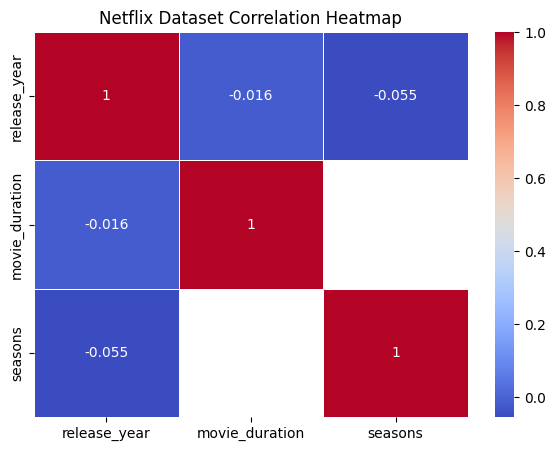

In [170]:
#visualize the correlation

plt.figure(figsize=(7,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)

plt.title('Netflix Dataset Correlation Heatmap')
plt.show()

### Phase 15: Correlation Analysis

Performed correlation analysis on numerical variables using Pandas. The results showed almost no linear relationship between release year and movie duration (-0.016), or release year and TV show seasons (-0.055). The analysis also identified an undefined correlation between movie duration and seasons because these variables belong to different content types.

#Phase 16 – Final Insights & Business Recommendations.

###Analysis	Key finding
* Content type - Movies 68.77%, TV Shows 31.23%
* Release year - 2024 had the highest count (91)
* Content additions -	2026 showed 353 additions in your earlier output; future-dated records need investigation
* Genre	- Drama ranked first (382)
* Country	- USA (593), India (472)
* Rating - TV-MA ranked first (506)
* Movie duration -	Average 104.58 minutes
* TV Show seasons	- Average 2.17 seasons
* Directors & actors -	Top contributors had relatively close counts
* Monthly additions	- September highest, February lowest
* Correlation	- Very weak relationships between the numerical variablesList item





###Five major insights
1. Content Distribution: Movies represent 68.77% of Netflix's catalogue, showing a strong movie presence.



2. Genre Preference: Drama is the most represented genre, followed by Action.



3. Geographical Distribution: The USA and India contribute significantly more titles than other countries.



4. Movie Duration: Most movies are concentrated around 80–120 minutes.



5. TV Show Structure: Single-season shows are the most common, with an average of 2.17 seasons.

###Business Recommendations
1. Netflix could maintain its strong movie catalogue while exploring opportunities to expand TV show content.



2. Netflix could continue investing in Drama and Action while exploring less-represented genres.



3. Netflix could strengthen regional content strategies in countries with lower representation.



4. Netflix could consider the popularity of 80–120-minute movies when planning its movie catalogue.



5. Netflix could explore both limited-series formats and opportunities for successful shows to continue across multiple seasons.

# Phase 16: Final Insights & Business Recommendations

### Key Insights
1. Movies account for 68.77% of Netflix's content catalogue.
2. Drama is the most frequently represented genre.
3. The United States and India have the highest country-wise content representation.
4. The average movie duration is approximately 104.58 minutes.
5. Single-season TV shows are the most common.

### Business Recommendations
1. Explore opportunities to expand less-represented genres.
2. Maintain a balanced catalogue of Movies and TV Shows.
3. Consider expanding regional content in underrepresented markets.
4. Explore different movie durations and limited-series formats.

### Dataset Limitations
The dataset does not contain viewer engagement, watch time or audience preference information. Numerical variables also show very weak relationships, and movie duration and TV show seasons cannot be directly compared.

Therefore, the findings describe Netflix's content catalogue rather than actual viewer behaviour.

# Phase 17: **Project Conclusion**: ✅

## Project Summary

This project involved Exploratory Data Analysis (EDA) of the Netflix Movies and TV Shows dataset using Python.

The analysis included data understanding, data cleaning, content distribution, release trends, genre analysis, country-wise distribution, ratings, movie durations, TV show seasons, director and cast analysis, and correlation analysis.

## Key Findings

- Movies account for 68.77% of the dataset, while TV Shows account for 31.23%.
- Drama is the most frequently represented genre.
- The United States and India are the leading content-producing countries in the dataset.
- The average movie duration is approximately 104.58 minutes.
- Single-season TV Shows are the most common.
- September recorded the highest number of content additions.
- Numerical variables showed very weak correlations.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## Learning Outcomes

Through this project, I gained practical experience in:

- Data cleaning and preprocessing.
- Exploratory Data Analysis using Pandas.
- Data visualization using Matplotlib and Seaborn.
- Identifying patterns and trends.
- Statistical and correlation analysis.
- Drawing business insights from data.

## Final Conclusion

This project helped me understand how data analysis can transform raw datasets into meaningful insights. It strengthened my Python, data manipulation, visualization, and analytical thinking skills.

The analysis provides an overview of Netflix's content catalogue and demonstrates the importance of data-driven decision-making.